# 9i. Seasonal evolution of the 2026/27 polar vortex

Day-by-day evolution of the Northern Hemisphere stratospheric polar vortex at 10 hPa from October
2026 to April 2027 in the E3SM RTENSO2026 hindcasts from the 1 Feb, 1 May and 1 Aug 2026 starts. This
is the companion of notebook 8 (the 2026/27 El Niño) for the stratosphere. Each frame is one day:

* **Maps** (north-polar stereographic, 30°N-pole; North America at the bottom):
  * **Member row**: one fixed member per start (`MEMBERS`), chosen by hand before looking at the
    results, **not** because it has an SSW. Contours are the **raw** E3SM 10-hPa geopotential height
    (fixed levels every `STYLE["line"]` m), so they show the vortex the model simulates, including its bias.
  * **Ensemble-mean row** (`SHOW_ENSMEAN`): the pooled ensemble mean of each start, in dashed circles. A mean of
    many members is not a realization: it smooths away displacements and splits.
  * **Shading** (`SHADING = "anomaly"`, or `None` for contours only): the anomaly from each start's own
    Reanalysis climatology (`CLIM_METHOD = "direct"`: May 1981-2010, Feb and Aug the six 1985-2010 starts).
  * **Reference column**: the ERA5 1981-2010 climatology of the day, and the E3SM climatology of the day
    (May starts), both as raw contours with the same levels, so the model's weak vortex is visible.
* **U(60°N, 10 hPa) panel**: each start's member (solid) and ensemble mean (dashed), the member range
  (shading), the E3SM climatology and the ERA5 climatology ±1σ, drawn up to the frame day; below zero is
  easterly. SSW labels are off by default (`SHOW_SSW`).

Contour levels, shading levels, projection and dates are the same in every panel and frame, so a change
between panels is a change of the simulated vortex, not of the plot settings.

9h animates selected SSW members and 9g studies one event's mechanism; this notebook shows the
seasonal evolution without event-based selection. 9b-9f have the statistics behind them.

**Data.** Only existing caches are read: the daily map caches of native `eam.h1` `Z010`
(`strat_case.pooled_daily_maps`), the daily zonal means (`pooled_daily_zonal`) and the direct
climatologies (`rtenso_case.matched_climatology`); the anomaly adds the ensemble-mean offset between
the native daily `Z010` and the monthly `Z3` (`strat_case.map_lead_climatology`). Map helpers:
`util/vortex_plot.py`.

**Pooled ensembles:** as in notebooks 8-10 (`POOL`, 30 members per start; the bit-identical 1 Feb
2026 `clim` and `obs` runs count once, so that start has 20).

**The 9a-9i series** (polar vortex and SSWs in the RTENSO2026 2026 starts): `9a` builds and checks the
caches; `9b` model climatology; `9c` vortex forecast; `9d` SSW occurrence; `9e` ENSO/QBO background;
`9f` SSW dynamics; `9g` SSW mechanism (featured member vs controls); `9h` SSW-event animation; `9i`
seasonal-evolution animation. Shared loading: `util/strat_diag.py`; readers `util/strat_case.py`; maps
`util/vortex_plot.py`.

In [1]:
%matplotlib inline

import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

from IPython.display import Image, display
from matplotlib import animation
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from esp_lab.utils.filename_utils import figure_filename

from util import rtenso_case as rc
from util import strat_case as sc
from util import vortex_plot as vp

warnings.filterwarnings("ignore", message="invalid value encountered")
warnings.filterwarnings("ignore", message="Mean of empty slice")

### Run controls

In [2]:
NOTEBOOK = "9i_vortex_evolution_animation"   # outputs: rc.OUTPUT_ROOT/9i_vortex_evolution_animation/{figures,data}/
# "require": use the existing caches only (no raw-data build); "auto" builds a missing cache
derivation_mode = "require"
CLIM_METHOD = "direct"              # shading climatology: "direct" (each start's Reanalysis starts) or "lead_drift"

# Data locations (machine-specific)
OBSERVATION_ROOT = Path("/global/cfs/cdirs/e3sm/zhan391/data")                       # reference-data archive
ERA5_ZONAL_DIR = OBSERVATION_ROOT / "ERA5" / "1x1" / "daily_zonal"                    # ERA5 daily zonal means
SIMULATION_ROOT = Path("/global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/simulation")         # raw eam.h1 (cache keys only)
MAP_FILE = Path("/global/cfs/cdirs/e3sm/diagnostics/maps/map_ne30pg2_to_cmip6_180x360_aave.20200201.nc")

YEAR = 2026
EVENT_LABEL = "2026/27 polar vortex"
INIT_MONTHS = (2, 5, 8, 11)
MONTH_NAMES = {1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr", 5: "May", 6: "Jun", 7: "Jul", 8: "Aug",
               9: "Sep", 10: "Oct", 11: "Nov", 12: "Dec"}
INIT_COLORS = {2: "#1f77b4", 5: "#2ca02c", 8: "#9467bd", 11: "#d62728"}   # one colour per start (as notebook 8)
MODEL_PREFIX = rc.MODEL_PREFIX
POOL = {
    "Reanalysis-CLIM": f"{MODEL_PREFIX}_RTENSO2026_clim",
    "Reanalysis-OBS": f"{MODEL_PREFIX}_RTENSO2026_obs",
    "Reanalysis-NSIDC": f"{MODEL_PREFIX}_RTENSO2026_obs_ice_nsidc",
}

# One fixed member per start, chosen before looking at the results (here the first member of the clim case,
# present in every start); change it here, not according to what the member does.
MEMBERS = {2: "Reanalysis-CLIM:0", 5: "Reanalysis-CLIM:0", 8: "Reanalysis-CLIM:0", 11: "Reanalysis-CLIM:0"}

FRAMES = ("2026-10-01", "2027-04-30")      # first and last frame day
FRAME_STEP = 2                             # days between frames
PREVIEW_DAY = "2027-01-15"
STORYBOARD = ["2026-10-15", "2026-11-15", "2026-12-15", "2027-01-15", "2027-02-15", "2027-03-15", "2027-04-15"]

SHOW_ENSMEAN = True                 # ensemble-mean row under the member row
SHADING = "anomaly"                 # "anomaly": direct-climatology anomaly shading; None: raw contours only
SHOW_REFERENCE = True               # reference column: ERA5 and E3SM climatologies of the day (raw contours)
SHOW_SSW = False                    # mark the members' SSW central dates on the timeline
SSW = {"sep_days": 20, "recover_days": 10}
CLIM_YEARS = rc.CLIM_YEARS
LAT_MIN = 30.0
STYLE = {"ci": 100.0, "range": 1200.0, "cmap": "blue2red", "units": "m",
         "name": "10-hPa height anomaly",
         "line": 400.0, "line_levels": np.arange(26000.0, 33000.0, 400.0)}   # fixed absolute contour levels (m)
U60_YLIM = (-20.0, 55.0)

# Animation output (as notebook 8)
FPS = 6                    # frames per second (FRAME_STEP days each)
HOLD = 6                   # extra copies of the last frame, so a looping GIF pauses at the end
ANIM_DPI = 100             # 14 x 10 in at 100 dpi: 1400 x 1000 px
ANIM_FORMATS = ("gif", "video")   # "video": H.264 MP4 when ffmpeg has libx264, else VP9 WebM
SHOW_INLINE = True         # show the GIF in the notebook
fig_dpi = 200              # preview frame and storyboard

OUTDIR = rc.output_dir(NOTEBOOK, "data")
FIGDIR = rc.figure_dir(NOTEBOOK)

### Load the cached fields

For each start: the fixed member and the ensemble mean of the raw daily 10-hPa height, their anomalies
from the start's climatology (when `SHADING`), and U(60°N, 10 hPa) of every member. Only the frame days
are loaded (the map caches are opened lazily).

In [3]:
%%time
days = pd.date_range(FRAMES[0], FRAMES[1], freq="D")
frame_days = pd.date_range(FRAMES[0], FRAMES[1], freq=f"{FRAME_STEP}D")


def nh(da):
    return da.sel(lat=slice(LAT_MIN - 0.01, 90.0))


def on_days(da, d):
    return da.sel(time=d.values)


# ERA5: climatology of the 10-hPa height (maps, e3sm_diags zg) and of U(60N, 10 hPa) (daily zonal means)
z_clim_era5 = sc.daily_from_month_clim(nh(rc.obs_monthly_climatology("Z10", mode="auto")).load(), days.values)
e_u60 = sc.lat_mean(sc.era5_daily_zonal(ERA5_ZONAL_DIR, fields=("U",), plev=[10.0])["U"].sel(plev=10.0), sc.U60)
u_clim, u_std = sc.daily_climatology(e_u60, CLIM_YEARS)
doy = xr.DataArray(sc.noleap_doy(days.values), dims="time", coords={"time": days.values})
u60_era5_clim, u60_era5_std = u_clim.sel(doy=doy).drop_vars("doy"), u_std.sel(doy=doy).drop_vars("doy")

# Reanalysis zonal-mean climatologies of every start month (U(60N, 10 hPa) climatology of each start)
REF_ALL = {m: sc.monthly_zonal(rc.REFERENCE["case_prefix"], "Reanalysis", range(CLIM_YEARS[0], CLIM_YEARS[1] + 1), m,
                               mode=derivation_mode, verbose=False).sel(plev=[10.0])
           for m in rc.REFERENCE["init_months"] + rc.DIRECT_INIT_MONTHS}

fc = {}
for init in INIT_MONTHS:
    maps = sc.pooled_daily_maps(SIMULATION_ROOT, MAP_FILE, POOL, YEAR, init, mode=derivation_mode)
    zd = sc.pooled_daily_zonal(SIMULATION_ROOT, POOL, YEAR, init, mode=derivation_mode)
    if maps is None or zd is None:
        print(f"[init {MONTH_NAMES[init]}] no cached fields")
        continue
    mem = MEMBERS[init]
    if mem not in maps["member"].values:
        raise ValueError(f"{mem} is not a member of the {MONTH_NAMES[init]} start: {list(maps['member'].values)[:6]} ...")
    d = days[days.isin(pd.DatetimeIndex(maps["time"].values))]
    raw_mem = nh(on_days(maps.sel(member=mem), d)).load()
    raw_mean = nh(on_days(maps, d).mean("member")).load()
    clim = sc.map_lead_climatology(POOL, YEAR, init, maps, d.values, method=CLIM_METHOD, lat_min=LAT_MIN,
                                   mode="auto").load() if (SHADING or SHOW_REFERENCE) else None
    u60 = sc.lat_mean(zd["U"].sel(plev=10.0), sc.U60)
    fc[init] = {"days": d, "n": int(maps.sizes["member"]), "member": mem,
                "raw_mem": raw_mem, "raw_mean": raw_mean, "clim": clim,
                "anom_mem": raw_mem - clim if clim is not None else None,
                "anom_mean": raw_mean - clim if clim is not None else None,
                "u60_mem": u60.sel(member=mem), "u60_mean": u60.mean("member"),
                "u60_lo": u60.quantile(0.1, "member"), "u60_hi": u60.quantile(0.9, "member"),
                "u60_clim": sc.lat_mean(sc.daily_from_lead(
                    sc.lead_climatology(init, REF_ALL, None, method="direct")["U"].sel(plev=10.0), YEAR, init,
                    u60["time"].values), sc.U60).assign_coords(time=u60["time"]),
                "ssw": [t for t in sc.ssw_central_dates(u60.sel(member=mem).values, u60["time"].values, **SSW)
                        if pd.Timestamp(FRAMES[0]) <= t <= pd.Timestamp(FRAMES[1])]}
    print(f"[init {MONTH_NAMES[init]} {YEAR}] member {mem} of {fc[init]['n']}; {len(d)} days; "
          f"climatology: {clim.attrs.get('climatology_method', '') if clim is not None else 'none'}")

# E3SM climatology of the day for the reference column: the May starts (30 years), raw contours
ref_init = 5 if 5 in fc else next(iter(fc))
z_clim_e3sm = fc[ref_init]["clim"]

/global/cfs/cdirs/m4849/zhan391/work_package/e3sm_s2d_proc/diagnostic/util/strat_case.py:630: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 61. This could degrade performance. Instead, consider rechunking after loading.
  return xr.open_dataset(path, chunks={"time": 61})    # lazy: about 0.3 GB per case and start


/global/cfs/cdirs/m4849/zhan391/work_package/e3sm_s2d_proc/diagnostic/util/strat_case.py:630: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 61. This could degrade performance. Instead, consider rechunking after loading.
  return xr.open_dataset(path, chunks={"time": 61})    # lazy: about 0.3 GB per case and start


[Reanalysis-OBS 2026-02] repeats an already pooled case member for member; not pooled again


/global/cfs/cdirs/m4849/zhan391/work_package/e3sm_s2d_proc/diagnostic/util/strat_case.py:630: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 61. This could degrade performance. Instead, consider rechunking after loading.
  return xr.open_dataset(path, chunks={"time": 61})    # lazy: about 0.3 GB per case and start


[Reanalysis-OBS 2026-02] repeats an already pooled case member for member; not pooled again


[init Feb 2026] member Reanalysis-CLIM:0 of 20; 212 days; climatology: Reanalysis init02 starts 1985, 1990, 1995, 2000, 2005, 2010 (direct)


... (8 outputs left out)

/global/cfs/cdirs/m4849/zhan391/work_package/e3sm_s2d_proc/diagnostic/util/strat_case.py:630: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 61. This could degrade performance. Instead, consider rechunking after loading.
  return xr.open_dataset(path, chunks={"time": 61})    # lazy: about 0.3 GB per case and start


/global/cfs/cdirs/m4849/zhan391/work_package/e3sm_s2d_proc/diagnostic/util/strat_case.py:630: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 61. This could degrade performance. Instead, consider rechunking after loading.
  return xr.open_dataset(path, chunks={"time": 61})    # lazy: about 0.3 GB per case and start


/global/cfs/cdirs/m4849/zhan391/work_package/e3sm_s2d_proc/diagnostic/util/strat_case.py:630: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 61. This could degrade performance. Instead, consider rechunking after loading.
  return xr.open_dataset(path, chunks={"time": 61})    # lazy: about 0.3 GB per case and start


[init Nov 2026] member Reanalysis-CLIM:0 of 30; 181 days; climatology: Reanalysis init11 1981-2010
CPU times: user 2min 18s, sys: 12.3 s, total: 2min 30s
Wall time: 9min 6s


### Frame layout

Rows: the fixed members, then (`SHOW_ENSMEAN`) the ensemble means in dashed circles; columns: the
reference climatologies (`SHOW_REFERENCE`), then the starts in order. The U(60°N, 10 hPa) panel below
draws each start up to the frame day, with the rest faded, as the Niño3.4 panel of notebook 8.
`draw_frame` redraws only what changes, so it draws the animation frames, the preview and the storyboard
panels.

In [4]:
FIG = {
    "size": (14.0, 10.0 if SHOW_ENSMEAN else 7.4),
    "hspace": 0.32, "wspace": 0.04,
    "left": 0.05, "right": 0.98, "top": 0.89, "bottom": 0.07,
    "suptitle": 16, "day": 20, "title": 10.5, "label": 10.5, "tick": 9.5, "legend": 9.5, "badge": 9.5,
    "member_lw": 2.4, "mean_lw": 1.8, "faded_alpha": 0.22, "range_alpha": 0.15,
}
INITS = [i for i in INIT_MONTHS if i in fc]
ROWS = [("mem", "member")] + ([("mean", "ensemble mean")] if SHOW_ENSMEAN else [])


def map_kwargs():
    return {"style": STYLE if SHADING else None, "total_levels": STYLE["line_levels"]}


def lead_label(init, t):
    m = (t.year - YEAR) * 12 + t.month - init
    return f"lead {m}"


def panel_fields(key, t):
    # (anom, total, u60) of a map panel on day t; None where the panel has no data
    t = np.datetime64(pd.Timestamp(t), "ns")
    if key == "era5":
        return None, z_clim_era5.sel(time=t), float(u60_era5_clim.sel(time=t))
    if key == "e3sm":
        return None, z_clim_e3sm.sel(time=t) if t in z_clim_e3sm["time"].values else None, \
            float(fc[ref_init]["u60_clim"].sel(time=t)) if t in fc[ref_init]["u60_clim"]["time"].values else None
    row, init = key
    f = fc[init]
    if t not in f["raw_mem"]["time"].values:
        return None, None, None
    raw, anom = (f["raw_mem"], f["anom_mem"]) if row == "mem" else (f["raw_mean"], f["anom_mean"])
    u = f["u60_mem"] if row == "mem" else f["u60_mean"]
    return (anom.sel(time=t) if (SHADING and anom is not None) else None), raw.sel(time=t), float(u.sel(time=t))


def panel_title(key):
    if key == "era5":
        return f"ERA5 {CLIM_YEARS[0]}-{CLIM_YEARS[1]} climatology", "0.25"
    if key == "e3sm":
        return f"E3SM climatology ({MONTH_NAMES[ref_init]} starts)", "0.25"
    row, init = key
    if row == "mem":
        return f"1 {MONTH_NAMES[init]} start: {fc[init]['member'].replace('Reanalysis-', '')}", INIT_COLORS[init]
    return f"1 {MONTH_NAMES[init]} start: mean of {fc[init]['n']}", INIT_COLORS[init]


def draw_map(ax, state, key, t):
    anom, total, u = panel_fields(key, t)
    if total is None:
        fill_map_empty = "Before start" if key not in ("era5", "e3sm") and pd.Timestamp(t) < pd.Timestamp(YEAR, key[1], 1) else "No data"
        vp.fill_map(ax, state, empty=fill_map_empty)
        return
    lead = lead_label(key[1], pd.Timestamp(t)) if key not in ("era5", "e3sm") else ""
    prefix = "U60 clim" if key in ("era5", "e3sm") else ("U60 mean" if key[0] == "mean" else "U60")
    vp.fill_map(ax, state, anom, total, lead=lead, **map_kwargs(), **vp.u60_badge(u, prefix))


def build_figure():
    ncol = len(INITS) + (1 if SHOW_REFERENCE else 0)
    nrow = len(ROWS)
    fig = plt.figure(figsize=FIG["size"])
    ratios = [1.0] * nrow + [0.045, 0.62]
    gs = fig.add_gridspec(nrow + 2, ncol, height_ratios=ratios, hspace=FIG["hspace"], wspace=FIG["wspace"],
                          left=FIG["left"], right=FIG["right"], top=FIG["top"], bottom=FIG["bottom"])
    maps = {}
    for r, (row, row_label) in enumerate(ROWS):
        c0 = 0
        if SHOW_REFERENCE:
            key = "era5" if r == 0 else "e3sm"
            maps[key] = (fig.add_subplot(gs[r, 0], projection=vp.PROJ), False)
            c0 = 1
        for k, init in enumerate(INITS):
            maps[(row, init)] = (fig.add_subplot(gs[r, c0 + k], projection=vp.PROJ), row == "mean")
    state = {"maps": {}}
    for key, (ax, dashed) in maps.items():
        title, color = panel_title(key)
        state["maps"][key] = (ax, vp.setup_map(ax, title, lat_min=LAT_MIN, color=color, title_size=FIG["title"],
                                               badge_size=FIG["badge"], label_size=FIG["label"], dashed_frame=dashed))
    for r, (row, row_label) in enumerate(ROWS):
        y = gs[r, 0].get_position(fig)
        fig.text(0.012, (y.y0 + y.y1) / 2, "one member\n(a realization)" if row == "mem" else "ensemble mean\n(not a realization)",
                 rotation=90, ha="center", va="center", fontsize=FIG["label"], fontweight="bold",
                 color="k" if row == "mem" else "0.4")

    # colour bar (fixed levels) or a note on the contours
    cax = fig.add_subplot(gs[nrow, :])
    pos = cax.get_position()
    cax.set_position([pos.x0 + pos.width * 0.25, pos.y0, pos.width * 0.5, pos.height])
    if SHADING:
        levels, cmap, norm = vp.shading(STYLE)
        cbar = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), cax=cax, orientation="horizontal", extend="both",
                            ticks=np.arange(-STYLE["range"], STYLE["range"] + 1e-6, 4 * STYLE["ci"]))
        cbar.set_label(f"{STYLE['name']} from each start's {CLIM_METHOD} climatology ({STYLE['units']}); "
                       f"contours: raw E3SM 10-hPa height every {STYLE['line']:g} m", fontsize=FIG["label"])
        cbar.ax.tick_params(labelsize=FIG["tick"])
    else:
        cax.axis("off")
        cax.text(0.5, 0.5, f"contours: raw E3SM 10-hPa height every {STYLE['line']:g} m", ha="center", va="center",
                 fontsize=FIG["label"], transform=cax.transAxes)

    # U(60N, 10 hPa): faded full series (static), solid up to the frame day (dynamic)
    ax = fig.add_subplot(gs[nrow + 1, :])
    t_all = days.values
    ax.fill_between(t_all, u60_era5_clim - u60_era5_std, u60_era5_clim + u60_era5_std, color="0.88", lw=0, zorder=0)
    ax.plot(t_all, u60_era5_clim, color="0.5", lw=1.2, zorder=1)
    ax.axhline(0.0, color="k", lw=1.0, zorder=2)
    ax.text(0.995, 0.0, "easterly below 0 ", transform=ax.get_yaxis_transform(), ha="right", va="top",
            fontsize=FIG["tick"] - 1, color="0.3")
    lines = {}
    for init in INITS:
        f, color = fc[init], INIT_COLORS[init]
        sl = slice(days[0], days[-1])
        lo, hi = f["u60_lo"].sel(time=sl), f["u60_hi"].sel(time=sl)
        ax.fill_between(lo["time"].values, lo, hi, color=color, alpha=FIG["range_alpha"] * 0.5, lw=0)
        ax.plot(f["u60_clim"].sel(time=sl)["time"].values, f["u60_clim"].sel(time=sl), color=color, lw=1.0, ls=":", alpha=0.7)
        series = {}
        for key, lw, ls in (("u60_mem", FIG["member_lw"], "-"), ("u60_mean", FIG["mean_lw"], "--")):
            s = f[key].sel(time=sl)
            ax.plot(s["time"].values, s.values, color=color, lw=lw * 0.7, ls=ls, alpha=FIG["faded_alpha"])
            series[key] = (s, ax.plot([], [], color=color, lw=lw, ls=ls, zorder=4)[0])
        series["dot"] = ax.plot([], [], "o", color=color, ms=7, mec="k", mew=0.6, zorder=6)[0]
        if SHOW_SSW:
            for tt in f["ssw"]:
                ax.plot([tt], [0.0], marker="v", color=color, ms=9, mec="k", mew=0.6, zorder=6)
        lines[init] = series
    cursor = ax.axvline(days[0], color="0.2", lw=1.2, ls="--", zorder=3)
    ax.set_xlim(days[0], days[-1])
    ax.set_ylim(*U60_YLIM)
    ax.set_ylabel("U(60°N, 10 hPa) (m s$^{-1}$)", fontsize=FIG["label"])
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
    ax.tick_params(labelsize=FIG["tick"])
    ax.grid(alpha=0.25)
    handles = [Line2D([], [], color="0.3", lw=FIG["member_lw"], label="member (map row 1)"),
               Line2D([], [], color="0.3", lw=FIG["mean_lw"], ls="--", label="ensemble mean"),
               Patch(color="0.6", alpha=0.3, label="member 10-90%"),
               Line2D([], [], color="0.3", lw=1.0, ls=":", label="E3SM climatology"),
               Patch(color="0.88", label=f"ERA5 {CLIM_YEARS[0]}-{CLIM_YEARS[1]} ±1σ")]
    handles += [Line2D([], [], color=INIT_COLORS[i], lw=FIG["member_lw"], label=f"1 {MONTH_NAMES[i]} {YEAR} start") for i in INITS]
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=4, fontsize=FIG["legend"], frameon=False)

    fig.suptitle(f"E3SM RTENSO2026: {EVENT_LABEL} at 10 hPa", x=FIG["left"], ha="left", y=0.975,
                 fontsize=FIG["suptitle"], fontweight="bold")
    fig.text(FIG["left"], 0.94, f"Fixed members (not selected for events): "
             + ", ".join(f"{MONTH_NAMES[i]} {fc[i]['member'].replace('Reanalysis-', '')}" for i in INITS)
             + (f"; shading: anomaly from each start's {CLIM_METHOD} Reanalysis climatology" if SHADING else ""),
             fontsize=FIG["legend"], color="0.3")
    day_text = fig.text(FIG["right"], 0.975, "", ha="right", va="top", fontsize=FIG["day"], fontweight="bold")
    state.update(lines=lines, cursor=cursor, day_text=day_text)
    return fig, state


def draw_frame(state, t):
    t = pd.Timestamp(t)
    state["day_text"].set_text(f"{t:%d %B %Y}")
    for key, (ax, mstate) in state["maps"].items():
        draw_map(ax, mstate, key, t)
    tn = np.datetime64(t, "ns")
    for init, series in state["lines"].items():
        for key in ("u60_mem", "u60_mean"):
            s, line = series[key]
            part = s.sel(time=slice(None, tn))
            line.set_data(part["time"].values, part.values)
        s = series["u60_mem"][0]
        if tn in s["time"].values:
            series["dot"].set_data([t], [float(s.sel(time=tn))])
    state["cursor"].set_xdata([t, t])
    return []

### Preview: one frame

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/9i_vortex_evolution_animation/figures/fig_rtenso2026_winter20262027_z10_evolution_preview_20270115.png


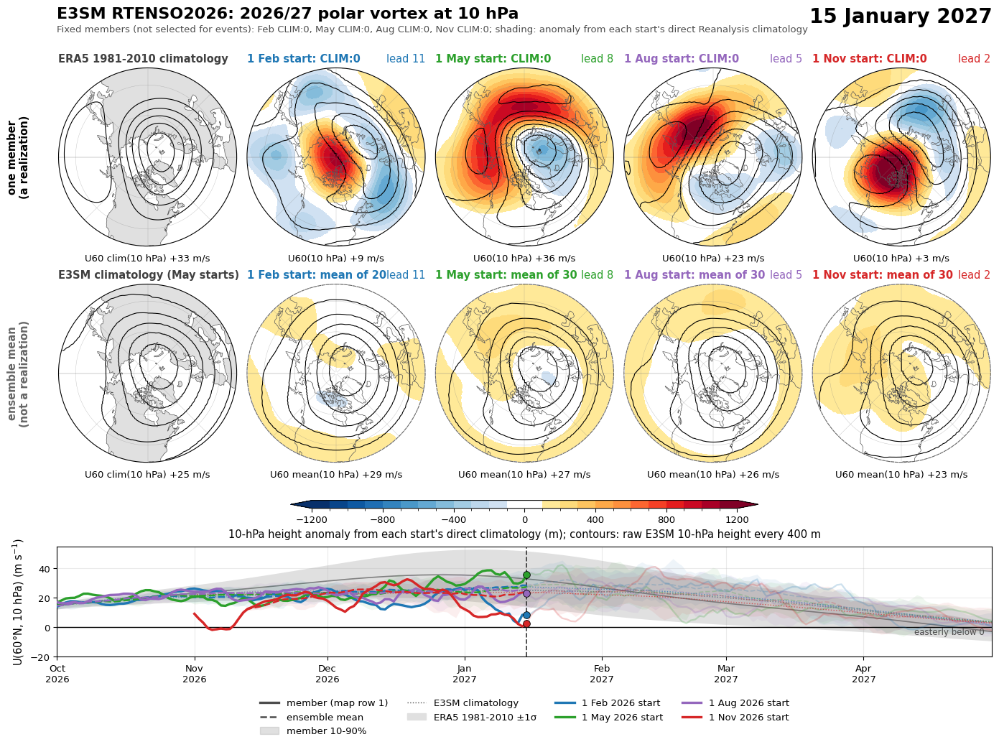

In [5]:
fig, state = build_figure()
draw_frame(state, PREVIEW_DAY)
path = FIGDIR / figure_filename("RTENSO2026", f"winter{YEAR}{YEAR + 1}", "Z10", "evolution", "preview",
                                pd.Timestamp(PREVIEW_DAY).strftime("%Y%m%d"), ext="png")
fig.savefig(path, dpi=fig_dpi)
print(path)
plt.show()

### Animation

One GIF and one video under `figures/`, one frame every `FRAME_STEP` days from `FRAMES[0]` to
`FRAMES[1]`, the last frame held for `HOLD` frames.

video: webm


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/9i_vortex_evolution_animation/figures/fig_rtenso2026_winter20262027_z10_evolution.gif (26.8 MB)


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/9i_vortex_evolution_animation/figures/fig_rtenso2026_winter20262027_z10_evolution.webm (5.8 MB)


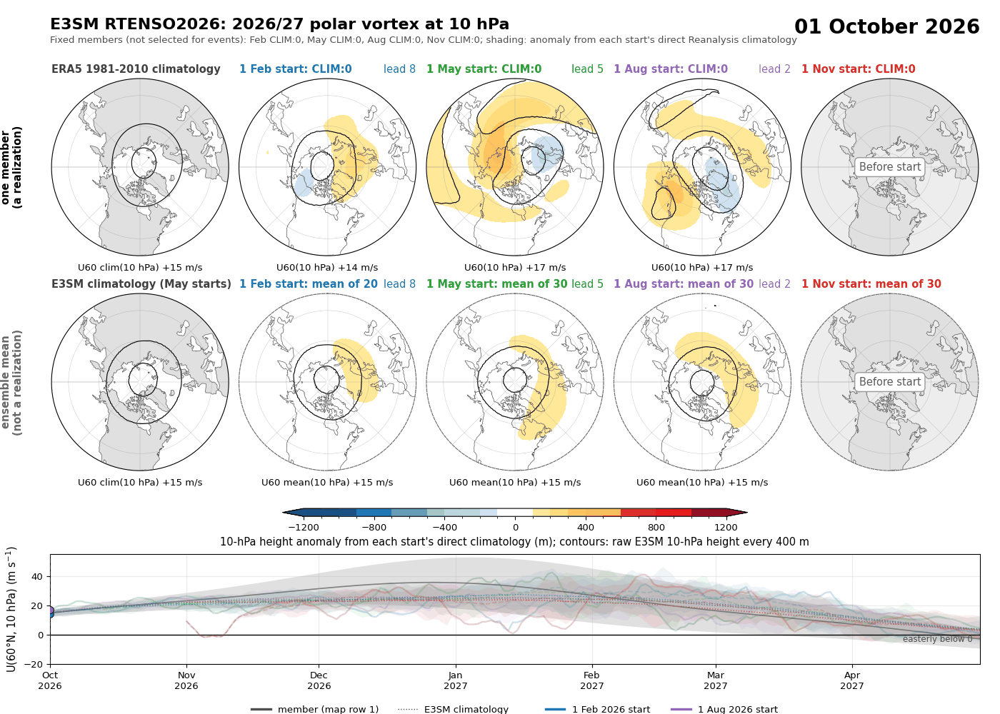

CPU times: user 12min 36s, sys: 33 s, total: 13min 9s
Wall time: 33min 9s


In [6]:
%%time
video_ext, video = vp.video_writer(FPS)
writers = {"gif": ("gif", lambda: animation.PillowWriter(fps=FPS)), "video": (video_ext, video)}
print(f"video: {video_ext or 'no ffmpeg video encoder; skipped'}")
sequence = list(frame_days) + [frame_days[-1]] * HOLD
fig, state = build_figure()
anim = animation.FuncAnimation(fig, lambda t: draw_frame(state, t), frames=sequence, blit=False, cache_frame_data=False)
anim_files = {}
for fmt in ANIM_FORMATS:
    ext, writer = writers[fmt]
    if writer is None:
        continue
    path = FIGDIR / figure_filename("RTENSO2026", f"winter{YEAR}{YEAR + 1}", "Z10", "evolution", ext=ext)
    anim.save(path, writer=writer(), dpi=ANIM_DPI)
    anim_files[ext] = path
    print(f"{path} ({path.stat().st_size / 1e6:.1f} MB)")
plt.close(fig)
if SHOW_INLINE and "gif" in anim_files:
    display(Image(filename=str(anim_files["gif"])))

### Storyboard

The `STORYBOARD` days in one static figure (rows: days; columns: the reference climatologies, then each
start's member and, with `SHOW_ENSMEAN`, its ensemble mean), for papers and handouts.

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/9i_vortex_evolution_animation/figures/fig_rtenso2026_winter20262027_z10_evolution_storyboard.png


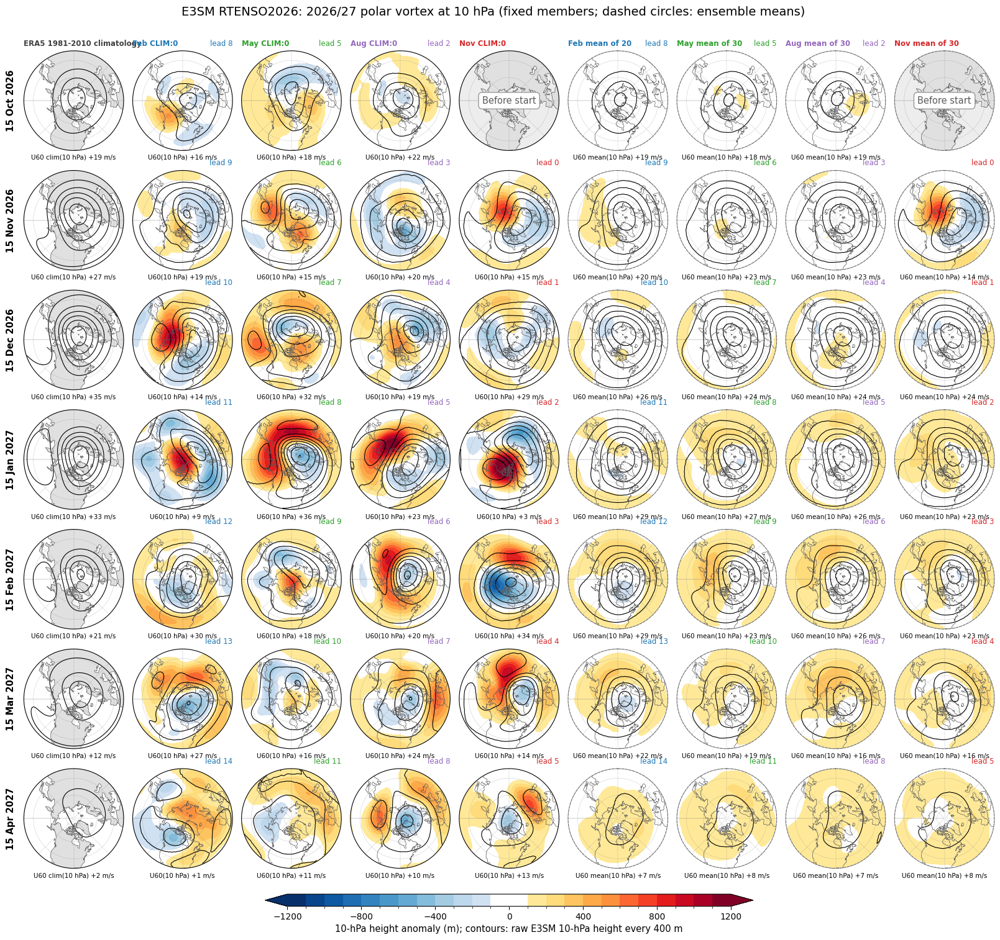

In [7]:
def storyboard():
    columns = (["era5"] if SHOW_REFERENCE else []) + [("mem", i) for i in INITS] + ([("mean", i) for i in INITS] if SHOW_ENSMEAN else [])
    rows = [pd.Timestamp(d) for d in STORYBOARD]
    fig, axes = plt.subplots(len(rows), len(columns), figsize=(2.25 * len(columns), 2.4 * len(rows) + 1.2),
                             subplot_kw={"projection": vp.PROJ}, squeeze=False, gridspec_kw={"hspace": 0.2, "wspace": 0.04})
    for r, t in enumerate(rows):
        for c, key in enumerate(columns):
            ax = axes[r, c]
            title, color = panel_title(key)
            mstate = vp.setup_map(ax, title.replace("1 ", "").replace(" start:", "") if r == 0 else "", lat_min=LAT_MIN,
                                  color=color, title_size=FIG["title"] - 2, badge_size=FIG["badge"] - 2,
                                  dashed_frame=key != "era5" and key[0] == "mean")
            draw_map(ax, mstate, key, t)
            if c == 0:
                ax.text(-0.13, 0.5, f"{t:%d %b %Y}", transform=ax.transAxes, rotation=90, ha="center", va="center",
                        fontsize=FIG["label"], fontweight="bold")
    if SHADING:
        levels, cmap, norm = vp.shading(STYLE)
        cbar = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=axes, orientation="horizontal", extend="both",
                            fraction=0.02, pad=0.03, shrink=0.5, aspect=40,
                            ticks=np.arange(-STYLE["range"], STYLE["range"] + 1e-6, 4 * STYLE["ci"]))
        cbar.set_label(f"{STYLE['name']} ({STYLE['units']}); contours: raw E3SM 10-hPa height every {STYLE['line']:g} m",
                       fontsize=FIG["label"])
    fig.suptitle(f"E3SM RTENSO2026: {EVENT_LABEL} at 10 hPa (fixed members; dashed circles: ensemble means)",
                 fontsize=FIG["suptitle"] - 2, y=0.92)
    return fig


fig = storyboard()
print(rc.save_figure(fig, NOTEBOOK, "RTENSO2026", f"winter{YEAR}{YEAR + 1}", "Z10", "evolution", "storyboard", dpi=fig_dpi))
plt.show()